In [ ]:
# Task 26: Sales Data Visualization

## Objective
Visualize sales data using bar charts and line charts to identify
patterns, comparisons, and trends.

## Deliverables
- Sales dataset
- Bar chart showing sales by product category
- Line chart showing monthly sales trends
- At least two observations from the visualizations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Create 12 monthly dates for 2025
months = pd.date_range(
    start="2025-01-01",
    periods=12,
    freq="MS"
)

# Monthly sales in Indian Rupees
sales_data = {
    "Electronics": [
        120000, 135000, 128000, 142000,
        150000, 158000, 165000, 172000,
        168000, 180000, 195000, 210000
    ],

    "Clothing": [
        85000, 90000, 88000, 95000,
        98000, 102000, 110000, 115000,
        112000, 120000, 130000, 145000
    ],

    "Furniture": [
        70000, 72000, 75000, 78000,
        80000, 83000, 85000, 90000,
        88000, 94000, 100000, 108000
    ]
}

# Convert the data into individual sales records
records = []

for category, values in sales_data.items():
    for month, sales in zip(months, values):
        records.append({
            "month": month,
            "category": category,
            "sales_inr": sales
        })

df = pd.DataFrame(records)

print("Sales dataset created successfully!")
print("Total records:", len(df))

display(df.head(10))

Sales dataset created successfully!
Total records: 36


,month,category,sales_inr
0,2025-01-01,Electronics,120000
1,2025-02-01,Electronics,135000
2,2025-03-01,Electronics,128000
3,2025-04-01,Electronics,142000
4,2025-05-01,Electronics,150000
5,2025-06-01,Electronics,158000
6,2025-07-01,Electronics,165000
7,2025-08-01,Electronics,172000
8,2025-09-01,Electronics,168000
9,2025-10-01,Electronics,180000


In [3]:
# Export the original dataset
df.to_csv(
    "sales_dataset.csv",
    index=False,
    date_format="%Y-%m-%d"
)

# Load the CSV using Pandas
df = pd.read_csv(
    "sales_dataset.csv",
    parse_dates=["month"]
)

print("Sales dataset loaded successfully!")

display(df.head())

Sales dataset loaded successfully!


,month,category,sales_inr
0,2025-01-01,Electronics,120000
1,2025-02-01,Electronics,135000
2,2025-03-01,Electronics,128000
3,2025-04-01,Electronics,142000
4,2025-05-01,Electronics,150000


In [4]:
print("DATASET INFORMATION")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nDATA TYPES")
print(df.dtypes)

print("\nSUMMARY STATISTICS")
display(df.describe())

DATASET INFORMATION
Rows: 36
Columns: 3

COLUMN NAMES
['month', 'category', 'sales_inr']

DATA TYPES
month        datetime64[ns]
category             object
sales_inr             int64
dtype: object

SUMMARY STATISTICS


,month,sales_inr
count,36,36.000000
mean,2025-06-16 12:00:00,117666.666667
min,2025-01-01 00:00:00,70000.000000
25%,2025-03-24 06:00:00,88000.000000
50%,2025-06-16 00:00:00,109000.000000
75%,2025-09-08 12:00:00,142750.000000
max,2025-12-01 00:00:00,210000.000000
std,NaN,37304.155265


In [5]:
category_sales = (
    df.groupby("category")["sales_inr"]
    .sum()
    .reset_index()
    .sort_values(
        by="sales_inr",
        ascending=False
    )
)

print("TOTAL SALES BY PRODUCT CATEGORY")

display(category_sales)

TOTAL SALES BY PRODUCT CATEGORY


,category,sales_inr
1,Electronics,1923000
0,Clothing,1290000
2,Furniture,1023000


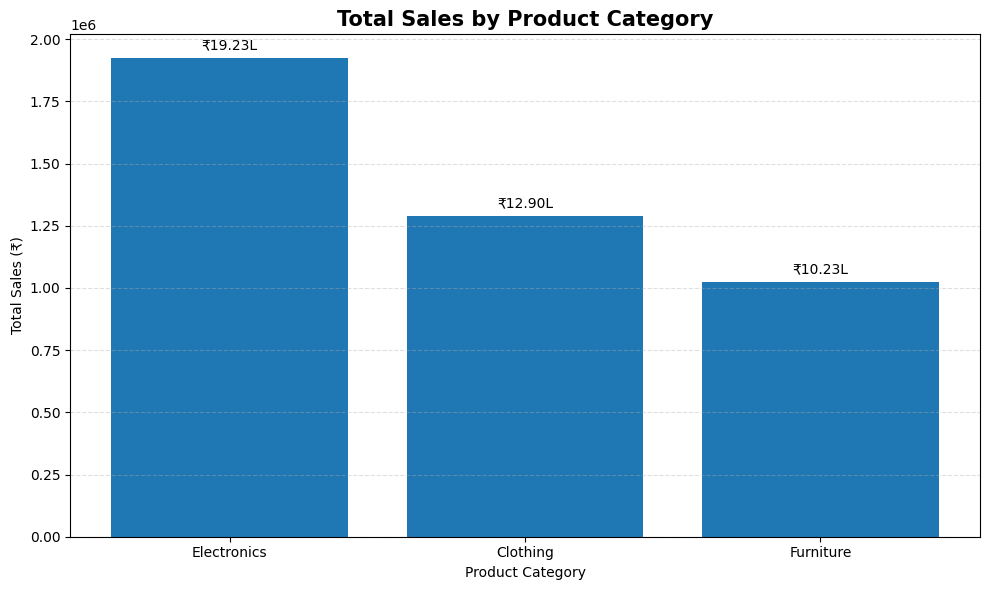

In [6]:
# Create a folder for charts
Path("charts").mkdir(exist_ok=True)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    category_sales["category"],
    category_sales["sales_inr"]
)

# Add values above the bars
labels = [
    f"₹{value/100000:.2f}L"
    for value in category_sales["sales_inr"]
]

plt.bar_label(
    bars,
    labels=labels,
    padding=4
)

plt.title(
    "Total Sales by Product Category",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Product Category")
plt.ylabel("Total Sales (₹)")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()

plt.savefig(
    "charts/sales_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
monthly_sales_summary = (
    df.groupby("month")["sales_inr"]
    .sum()
    .reset_index()
    .sort_values("month")
)

monthly_sales_summary["month_name"] = (
    monthly_sales_summary["month"].dt.strftime("%b")
)

print("MONTHLY SALES SUMMARY")

display(monthly_sales_summary)

MONTHLY SALES SUMMARY


,month,sales_inr,month_name
0,2025-01-01,275000,Jan
1,2025-02-01,297000,Feb
2,2025-03-01,291000,Mar
3,2025-04-01,315000,Apr
4,2025-05-01,328000,May
5,2025-06-01,343000,Jun
6,2025-07-01,360000,Jul
7,2025-08-01,377000,Aug
8,2025-09-01,368000,Sep
9,2025-10-01,394000,Oct


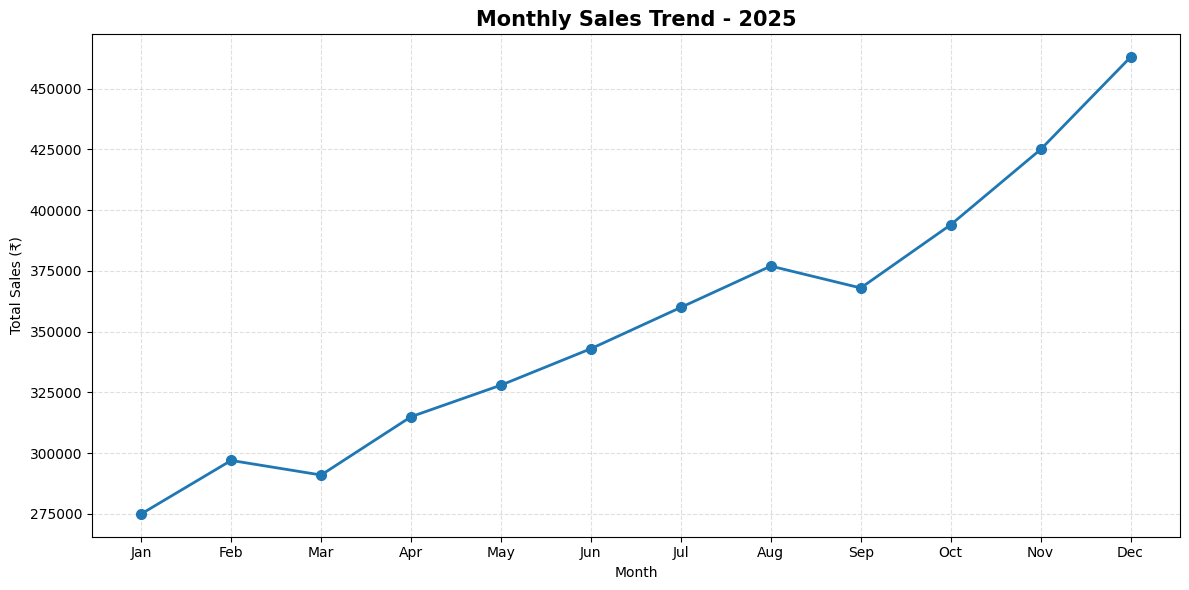

In [8]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales_summary["month_name"],
    monthly_sales_summary["sales_inr"],
    marker="o",
    linewidth=2,
    markersize=7
)

plt.title(
    "Monthly Sales Trend - 2025",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Total Sales (₹)")

plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()

plt.savefig(
    "charts/monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
# Highest and lowest selling categories
top_category = category_sales.iloc[0]
lowest_category = category_sales.iloc[-1]

# Highest and lowest sales months
best_month = monthly_sales_summary.loc[
    monthly_sales_summary["sales_inr"].idxmax()
]

worst_month = monthly_sales_summary.loc[
    monthly_sales_summary["sales_inr"].idxmin()
]

# Calculate January-to-December growth
first_month_sales = monthly_sales_summary.iloc[0]["sales_inr"]
last_month_sales = monthly_sales_summary.iloc[-1]["sales_inr"]

growth_percentage = (
    (last_month_sales - first_month_sales)
    / first_month_sales
) * 100

total_sales = df["sales_inr"].sum()

print("=" * 55)
print("          SALES DATA VISUALIZATION OBSERVATIONS")
print("=" * 55)

print(
    f"\n1. Highest selling category: "
    f"{top_category['category']} "
    f"(₹{top_category['sales_inr']:,.0f})"
)

print(
    f"\n2. Lowest selling category: "
    f"{lowest_category['category']} "
    f"(₹{lowest_category['sales_inr']:,.0f})"
)

print(
    f"\n3. Highest sales month: "
    f"{best_month['month_name']} "
    f"(₹{best_month['sales_inr']:,.0f})"
)

print(
    f"\n4. Lowest sales month: "
    f"{worst_month['month_name']} "
    f"(₹{worst_month['sales_inr']:,.0f})"
)

print(
    f"\n5. January to December sales growth: "
    f"{growth_percentage:.2f}%"
)

print(f"\n6. Total annual sales: ₹{total_sales:,.0f}")

          SALES DATA VISUALIZATION OBSERVATIONS

1. Highest selling category: Electronics (₹1,923,000)

2. Lowest selling category: Furniture (₹1,023,000)

3. Highest sales month: Dec (₹463,000)

4. Lowest sales month: Jan (₹275,000)

5. January to December sales growth: 68.36%

6. Total annual sales: ₹4,236,000


In [10]:
# Save category-wise sales summary
category_sales.to_csv(
    "category_sales_summary.csv",
    index=False
)

# Save monthly sales summary
monthly_sales_summary.to_csv(
    "monthly_sales_summary.csv",
    index=False
)

print("Sales summary files saved successfully!")

Sales summary files saved successfully!


In [11]:
print("FINAL SALES ANALYSIS SUMMARY")

print("Total sales:", f"₹{total_sales:,.0f}")
print("Total transactions:", len(df))
print("Number of product categories:", df["category"].nunique())
print("Number of months:", df["month"].nunique())

print("\nCategory-wise sales:")
display(category_sales)

print("\nMonthly sales:")
display(monthly_sales_summary)

FINAL SALES ANALYSIS SUMMARY
Total sales: ₹4,236,000
Total transactions: 36
Number of product categories: 3
Number of months: 12

Category-wise sales:


,category,sales_inr
1,Electronics,1923000
0,Clothing,1290000
2,Furniture,1023000



Monthly sales:


,month,sales_inr,month_name
0,2025-01-01,275000,Jan
1,2025-02-01,297000,Feb
2,2025-03-01,291000,Mar
3,2025-04-01,315000,Apr
4,2025-05-01,328000,May
5,2025-06-01,343000,Jun
6,2025-07-01,360000,Jul
7,2025-08-01,377000,Aug
8,2025-09-01,368000,Sep
9,2025-10-01,394000,Oct


In [12]:
from google.colab import files

files.download("sales_dataset.csv")
files.download("category_sales_summary.csv")
files.download("monthly_sales_summary.csv")
files.download("charts/sales_by_category.png")
files.download("charts/monthly_sales_trend.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>